# Classification de la qualité du vin

Projet Machine Learning 
MOUTTAKI Yasmine & THOMAS Soline

## 1. Contexte et Objectif

Nous voulons prédire si un vin est bon (note de qualité d'au moins 7) à partir de 11 mesures physico-chimiques : acidité, pH, alcool, sucre résiduel, etc.

Les vins rouges et blancs sont traités ensemble dans un seul modèle. Comme il n'y a que 19 % de bons vins, nous utilisons `class_weight="balanced"`. Nous comparons cinq modèles : régression logistique, k-NN, arbre de décision, SVM et Random Forest.

In [1]:
import os
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform, randint

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import mutual_info_classif, RFE
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
sns.set_theme(style="whitegrid")

## 2. Modalités du projet

### 2.1 Prétraitement des données

#### - Chargement des données et statistiques descriptives.

In [2]:
dossier = "data" if os.path.exists("data") else "../data"

rouge = pd.read_csv(dossier + "/winequality-red.csv", sep=";")
blanc = pd.read_csv(dossier + "/winequality-white.csv", sep=";")

variables = [c for c in rouge.columns if c != "quality"]

print("Rouge :", rouge.shape)
print("Blanc :", blanc.shape)
print(len(variables), "variables :", variables)

Rouge : (1599, 12)
Blanc : (4898, 12)
11 variables : ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']


#### 2.1.a Fusion des vins rouges et blancs
Nous avons mis les deux fichiers l'un sous l'autre et ajouté une colonne couleur. Cette colonne sert seulement à l'analyse, ce n'est pas une variable du modèle.

In [3]:
rouge["couleur"] = "rouge"
blanc["couleur"] = "blanc"
df = pd.concat([rouge, blanc], ignore_index=True)

print(df.shape)
df.head()

(6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,couleur
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,rouge
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,rouge
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,rouge
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,rouge
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,rouge


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  couleur               6497 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 660.0 KB


In [5]:
df[variables + ["quality"]].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.215,1.296,3.800,6.400,7.000,7.700,15.900
volatile acidity,6497.0,0.340,0.165,0.080,0.230,0.290,0.400,1.580
citric acid,6497.0,0.319,0.145,0.000,0.250,0.310,0.390,1.660
residual sugar,6497.0,5.443,4.758,0.600,1.800,3.000,8.100,65.800
chlorides,6497.0,0.056,0.035,0.009,0.038,0.047,0.065,0.611
free sulfur dioxide,6497.0,30.525,17.749,1.000,17.000,29.000,41.000,289.000
total sulfur dioxide,6497.0,115.745,56.522,6.000,77.000,118.000,156.000,440.000
density,6497.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039
pH,6497.0,3.219,0.161,2.720,3.110,3.210,3.320,4.010
sulphates,6497.0,0.531,0.149,0.220,0.430,0.510,0.600,2.000


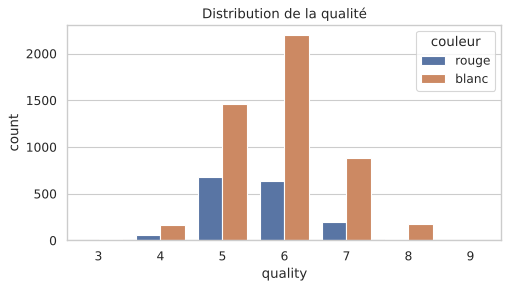

In [6]:
plt.figure(figsize=(7, 3.5))
sns.countplot(x="quality", hue="couleur", data=df)
plt.title("Distribution de la qualité")
plt.show()

Résultat : il y a 6497 vins (1599 rouges et 4898 blancs), 11 variables numériques et aucune valeur manquante. La note va de 3 à 9 et la plupart des vins ont 5, 6 ou 7.

Les échelles sont très différentes (le SO₂ total monte à 440, les chlorures valent environ 0,05). Nous standardiserons donc pour certains modèles.

#### - Gestion des valeurs manquantes et détection des valeurs aberrantes.

In [7]:
print("Valeurs manquantes :", df.isna().sum().sum())
print("Doublons :", df.duplicated().sum(), "sur", len(df))

df = df.drop_duplicates().reset_index(drop=True)
print("Après suppression des doublons :", df.shape)

Valeurs manquantes : 0
Doublons : 1177 sur 6497
Après suppression des doublons : (5320, 13)


Nous avons supprimé les doublons : un même vin dans le train et dans le test fausserait l'évaluation.

Pour les valeurs aberrantes, nous avons utilisé la règle de l'IQR : une valeur est aberrante si elle est en dessous de Q1 − 1,5×IQR ou au-dessus de Q3 + 1,5×IQR.

In [8]:
q1 = df[variables].quantile(0.25)
q3 = df[variables].quantile(0.75)
iqr = q3 - q1
outliers = (df[variables] < q1 - 1.5 * iqr) | (df[variables] > q3 + 1.5 * iqr)

pd.DataFrame({"nb_outliers": outliers.sum(), "% des vins": (outliers.mean() * 100).round(1)}).sort_values("nb_outliers", ascending=False)

,nb_outliers,% des vins
fixed acidity,304,5.7
volatile acidity,279,5.2
chlorides,237,4.5
sulphates,163,3.1
citric acid,143,2.7
residual sugar,141,2.7
pH,49,0.9
free sulfur dioxide,44,0.8
total sulfur dioxide,10,0.2
density,3,0.1


Résultat : il n'y a aucune valeur manquante. Il y avait 1177 doublons (240 en rouge, 937 en blanc), il reste 5320 vins.

Les valeurs aberrantes touchent de 0 % à 5,7 % des vins selon la variable. Nous les gardons : ce sont de vraies mesures et un vin exceptionnel peut être un bon vin.

#### - Encodage correct des variables catégorielles (si présentes).

In [9]:
print(df.dtypes[df.dtypes == "object"])

df["blanc"] = (df["couleur"] == "blanc").astype(int)
df[["couleur", "blanc"]].value_counts()

Series([], dtype: object)


,,count
couleur,blanc,
blanc,1,3961
rouge,0,1359


La couleur est la seule variable catégorielle (du texte). Nous l'avons codée en 0 et 1 dans la colonne blanc. Elle sert seulement à l'analyse.

#### - Transformation du problème en classification binaire (qualité ≥ 7 donc bon vin).
Nous avons créé la colonne good : 1 si la note est d'au moins 7, 0 sinon.

In [10]:
df["good"] = (df["quality"] >= 7).astype(int)
df[["quality", "good"]].drop_duplicates().sort_values("quality")

,quality,good
400,3,0
16,4,0
0,5,0
3,6,0
6,7,1
235,8,1
2012,9,1


#### - Analyse de la distribution des classes pour vérifier l'équilibre du jeu de données.

Pourcentage de bons vins (tous les vins) : 19.0 %
Accuracy d'un modèle qui répond toujours 'pas bon' : 81.0 %

Pourcentage de bons vins par couleur :
couleur
blanc    20.8
rouge    13.5
Name: good, dtype: float64


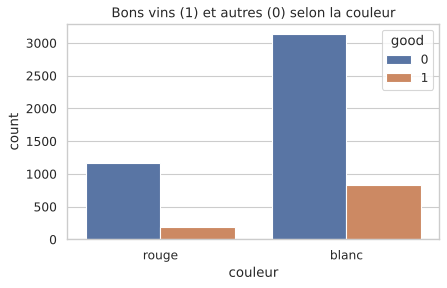

In [11]:
print("Pourcentage de bons vins (tous les vins) :", round(df["good"].mean() * 100, 1), "%")
print("Accuracy d'un modèle qui répond toujours 'pas bon' :", round((1 - df["good"].mean()) * 100, 1), "%")
print()
print("Pourcentage de bons vins par couleur :")
print((df.groupby("couleur")["good"].mean() * 100).round(1))

plt.figure(figsize=(6, 3.5))
sns.countplot(x="couleur", hue="good", data=df)
plt.title("Bons vins (1) et autres (0) selon la couleur")
plt.show()

Résultat : il y a 19,0 % de bons vins. Un modèle qui répond toujours « pas bon » a 81,0 % de bonnes réponses sans rien comprendre. Nous n'utiliserons donc pas l'accuracy pour choisir, mais la précision, le rappel, le F1 et l'AUC.

Par couleur, il y a 13,5 % de bons vins en rouge et 20,8 % en blanc.

#### 2.1.b Séparation train / test
Nous avons mis 20 % des vins de côté pour le test (1064 vins). Le test ne sert jamais à choisir un réglage. La séparation est faite avant les analyses suivantes pour qu'elles utilisent seulement le train. Avec `stratify=y`, il y a la même proportion de bons vins dans les deux jeux.

In [12]:
X = df[variables]
y = df["good"]
X_train11, X_test11, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print("Train :", len(y_train), "vins | classe 0 :", (y_train == 0).sum(), "| classe 1 :", (y_train == 1).sum())
print("Test  :", len(y_test), "vins | bons vins :", round(y_test.mean() * 100, 1), "%")

Train : 4256 vins | classe 0 : 3449 | classe 1 : 807
Test  : 1064 vins | bons vins : 19.0 %


#### - Analyse des corrélations entre les variables.
Nous avons calculé les corrélations sur le train seulement.

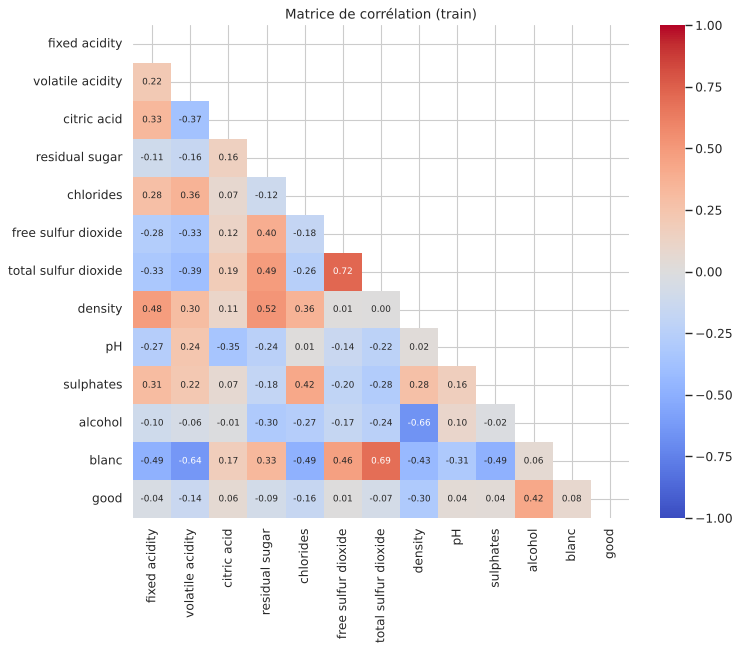

In [13]:
train = df.loc[X_train11.index]

corr = train[variables + ["blanc", "good"]].corr()
masque = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(10, 8))
sns.heatmap(corr, mask=masque, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, annot_kws={"size": 8})
plt.title("Matrice de corrélation (train)")
plt.show()

In [14]:
print("Corrélation avec la cible 'good' :")
print(corr["good"].drop("good").round(2).sort_values(key=abs, ascending=False))

print()
print("Paires de variables très corrélées (|r| >= 0.6) :")
for i, a in enumerate(variables):
    for b in variables[i + 1:]:
        if abs(corr.loc[a, b]) >= 0.6:
            print(a, "/", b, ":", round(corr.loc[a, b], 2))

Corrélation avec la cible 'good' :
alcohol                 0.42
density                -0.30
chlorides              -0.16
volatile acidity       -0.14
residual sugar         -0.09
blanc                   0.08
total sulfur dioxide   -0.07
citric acid             0.06
fixed acidity          -0.04
sulphates               0.04
pH                      0.04
free sulfur dioxide     0.01
Name: good, dtype: float64

Paires de variables très corrélées (|r| >= 0.6) :
free sulfur dioxide / total sulfur dioxide : 0.72
density / alcohol : -0.66


Résultat : l'alcool est la variable la plus liée à la qualité (0,42), puis la densité (−0,30), les chlorures (−0,16) et l'acidité volatile (−0,14). Les autres sont proches de 0, donc le problème est difficile.

Deux paires de variables se ressemblent : SO₂ libre et SO₂ total (0,72), densité et alcool (−0,66). Nous les gardons.

#### - Visualisations (matrice de corrélation, histogrammes, boxplots).
Nous avons tracé la matrice de corrélation (au-dessus), les histogrammes et les boxplots du train.

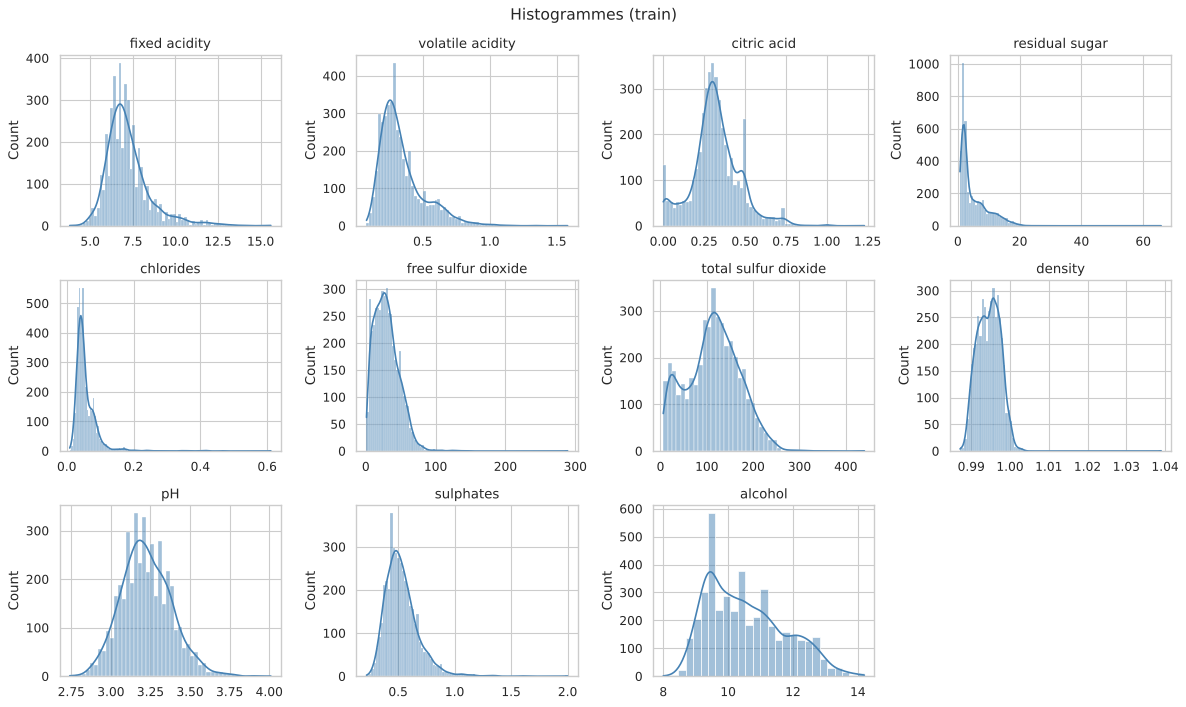

,0
fixed acidity,1.67
volatile acidity,1.52
citric acid,0.38
residual sugar,1.77
chlorides,5.55
free sulfur dioxide,1.53
total sulfur dioxide,0.10
density,0.80
pH,0.35
sulphates,1.75


In [15]:
fig, axes = plt.subplots(3, 4, figsize=(15, 9))
for ax, col in zip(axes.ravel(), variables):
    sns.histplot(train[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(col)
    ax.set_xlabel("")
axes.ravel()[-1].axis("off")
plt.suptitle("Histogrammes (train)", fontsize=14)
plt.tight_layout()
plt.show()

train[variables].skew().round(2)

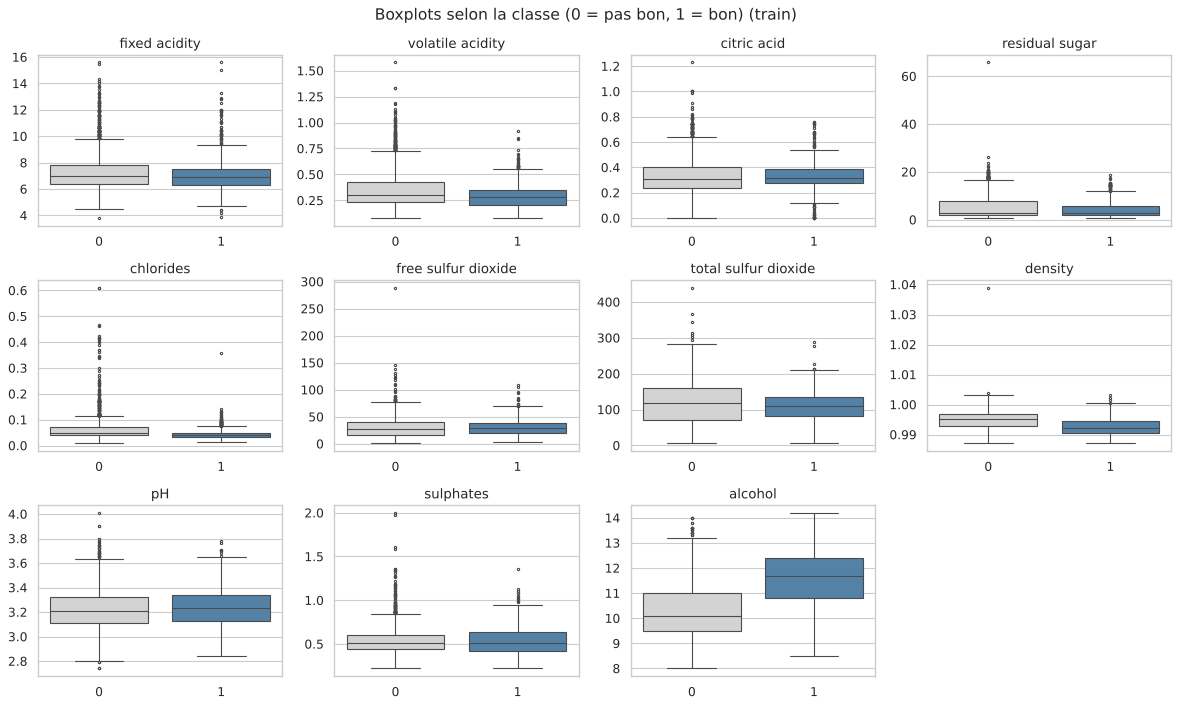

In [16]:
fig, axes = plt.subplots(3, 4, figsize=(15, 9))
for ax, col in zip(axes.ravel(), variables):
    sns.boxplot(x="good", y=col, data=train, ax=ax, hue="good", palette=["lightgray", "steelblue"], legend=False, fliersize=2)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")
axes.ravel()[-1].axis("off")
plt.suptitle("Boxplots selon la classe (0 = pas bon, 1 = bon) (train)", fontsize=14)
plt.tight_layout()
plt.show()

Résultat : plusieurs variables sont étalées vers la droite, surtout les chlorures (asymétrie de 5,55). Elles ne suivent pas une forme en cloche.

Sur les boxplots, les bons vins ont plus d'alcool. La densité, les chlorures, l'acidité volatile et le sucre résiduel sont un peu plus bas pour les bons vins. Pour les autres variables, les boîtes se chevauchent.

#### - Utilisation de méthodes de sélection de variables basées sur les méthodes vues en cours.
Nous avons mesuré l'importance des 11 variables avec trois familles de méthodes du cours, sur le train : le filtre (corrélation de Pearson et information mutuelle), le wrapper (RFE avec une régression logistique, rang 1 = variable gardée) et l'embedded (importance d'une Random Forest).

In [17]:
X_std = StandardScaler().fit_transform(X_train11)

pearson = X_train11.apply(lambda col: abs(np.corrcoef(col, y_train)[0, 1]))
info_mutuelle = pd.Series(mutual_info_classif(X_train11, y_train, random_state=42), index=variables)
rfe = RFE(LogisticRegression(max_iter=1000), n_features_to_select=5).fit(X_std, y_train)
foret = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(X_train11, y_train)

importance = pd.DataFrame({"Pearson |r|": pearson, "Info mutuelle": info_mutuelle,
                           "Rang RFE": rfe.ranking_, "Importance RF": foret.feature_importances_}, index=variables)
importance.sort_values("Importance RF", ascending=False).round(3)

,Pearson |r|,Info mutuelle,Rang RFE,Importance RF
alcohol,0.423,0.098,1,0.170
density,0.298,0.058,1,0.121
chlorides,0.159,0.032,6,0.088
total sulfur dioxide,0.074,0.029,4,0.084
volatile acidity,0.143,0.028,1,0.083
sulphates,0.038,0.009,3,0.081
residual sugar,0.086,0.010,1,0.081
free sulfur dioxide,0.005,0.014,5,0.079
pH,0.042,0.008,2,0.075
citric acid,0.058,0.021,7,0.071


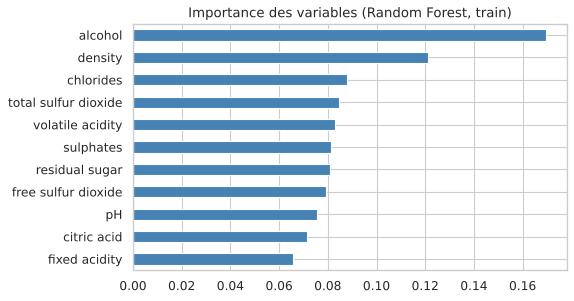

In [18]:
importance["Importance RF"].sort_values().plot.barh(color="steelblue", figsize=(7, 4))
plt.title("Importance des variables (Random Forest, train)")
plt.show()

Résultat : l'alcool est en tête pour toutes les méthodes. La densité est deuxième, mais elle est liée à l'alcool. Les autres variables ont des importances proches (0,07 à 0,09).

Aucune variable n'est clairement inutile, nous gardons les 11.

### 2.2 Modélisation et évaluation

#### - Modèles envisagés : régression logistique, k-NN, arbre de décision, Naive Bayes, SVM.
Nous testons la régression logistique, le k-NN, l'arbre de décision et le SVM, plus la Random Forest (cours séance 6). Nous n'avons pas gardé Naive Bayes : il suppose que les variables sont indépendantes, alors que les nôtres sont corrélées.

#### - Justification du choix des modèles selon :
- Leurs propriétés théoriques (linéaires vs non linéaires).
- Leur adaptabilité au type de données (distributions continues, bruit, etc.).

Un modèle linéaire sépare les classes avec une droite. Un modèle non linéaire peut faire une frontière courbe.

| Modèle | Type | Pourquoi dans notre cas |
|---|---|---|
| Régression logistique | Linéaire | Le plus simple, et on peut lire le rôle de chaque variable. Mais une droite est peut-être trop simple. |
| k-NN | Non linéaire | Un vin est classé comme ses voisins les plus proches. Il est sensible au bruit et à l'échelle des variables. |
| Arbre de décision | Non linéaire | Une suite de questions (« alcool supérieur à 11 ? »), facile à lire. Mais il apprend facilement le bruit par cœur. |
| SVM (noyau RBF) | Non linéaire | Frontière courbe, adapté à des variables continues standardisées. |
| Random Forest | Non linéaire | Moyenne de beaucoup d'arbres : elle garde leur souplesse et elle apprend moins le bruit. |

Nos variables sont continues et leurs échelles sont très différentes, donc nous les standardisons. C'est nécessaire pour la régression logistique, le k-NN et le SVM.

Nous utilisons `class_weight="balanced"` : une erreur sur un bon vin (classe rare) coûte plus cher qu'une erreur sur un autre vin. Le k-NN n'a pas ce paramètre, il reste sans correction.

Nous présentons chaque modèle séparément, avec une courte justification, un exemple sur le train et un graphique. Le F1 donné est une moyenne en validation croisée à 5 plis.

#### 2.2.a Régression logistique

C'est un modèle linéaire : il fait une somme pondérée des 11 variables et la transforme en probabilité. Il est simple et ses coefficients se lisent. Sa frontière est une droite, ce qui peut être trop simple. Nous standardisons les variables.

F1 en validation croisée : 0.534


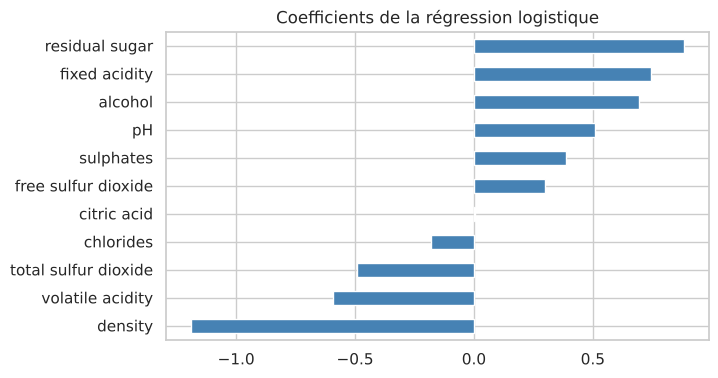

In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))
print("F1 en validation croisée :", cross_val_score(lr, X_train11, y_train, cv=5, scoring="f1").mean().round(3))

lr.fit(X_train11, y_train)
coef = pd.Series(lr[-1].coef_[0], index=X_train11.columns).sort_values()
coef.plot.barh(color="steelblue", figsize=(7, 4))
plt.title("Coefficients de la régression logistique")
plt.show()

Résultat : le F1 est de 0,534. Une barre vers la droite augmente la probabilité d'un bon vin, une barre vers la gauche la diminue. L'alcool est positif (+0,69). La densité (−1,19), l'acidité volatile (−0,59) et le SO₂ total (−0,49) sont négatifs.

Le sucre résiduel (+0,88) et l'acidité fixe (+0,75) ont aussi un coefficient élevé, à cause des variables qui se ressemblent (densité, alcool, sucre). Il faut donc lire ces coefficients avec prudence.

#### 2.2.b k-NN

C'est un modèle non linéaire. Pour classer un vin, il regarde ses k plus proches voisins dans le train et prend la classe majoritaire. Il est sensible à l'échelle (nous standardisons) et au bruit. Le choix de k est donc important.

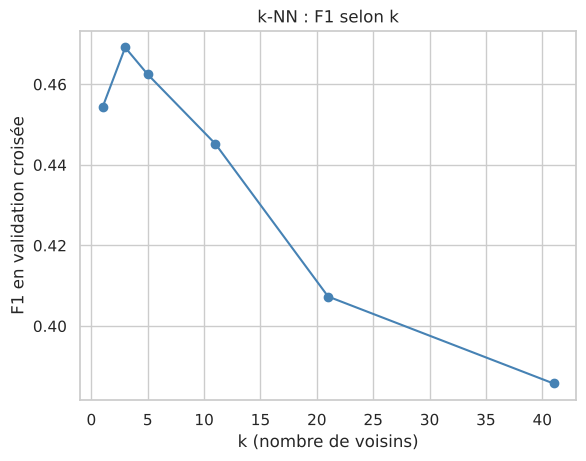

In [ ]:
valeurs_k = [1, 3, 5, 11, 21, 41]
f1_k = []
for k in valeurs_k:
    knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    f1_k.append(cross_val_score(knn, X_train11, y_train, cv=5, scoring="f1").mean())

plt.plot(valeurs_k, f1_k, marker="o", color="steelblue")
plt.xlabel("k (nombre de voisins)")
plt.ylabel("F1 en validation croisée")
plt.title("k-NN : F1 selon k")
plt.show()

Résultat : le F1 est le meilleur pour k entre 3 et 5 (environ 0,47), puis il baisse jusqu'à 0,39 pour k = 41. Avec beaucoup de voisins, la classe rare est noyée par l'autre.

#### 2.2.c Arbre de décision

C'est un modèle non linéaire qui pose des questions du type « alcool inférieur à telle valeur ? ». Il se lit facilement et n'a pas besoin de standardisation. Un arbre profond apprend le bruit du train par cœur. Nous limitons la profondeur à 3 pour que le dessin reste lisible.

F1 en validation croisée (profondeur 3) : 0.503


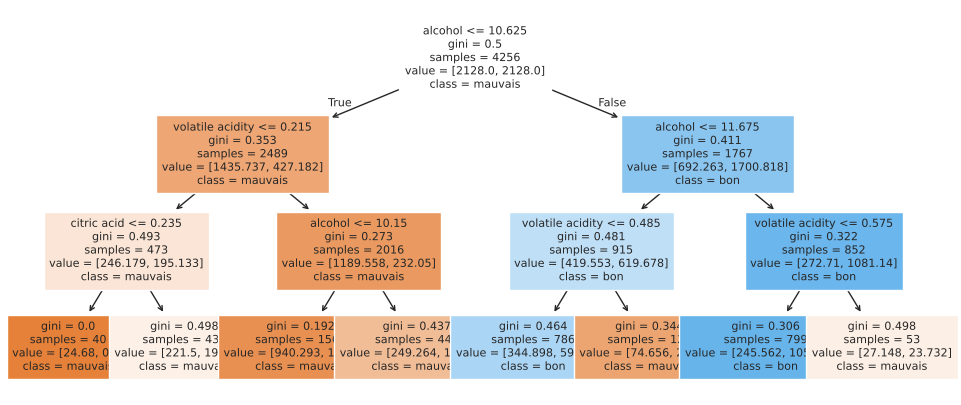

In [ ]:
arbre = DecisionTreeClassifier(max_depth=3, random_state=42, class_weight="balanced")
print("F1 en validation croisée (profondeur 3) :", cross_val_score(arbre, X_train11, y_train, cv=5, scoring="f1").mean().round(3))

from sklearn.tree import plot_tree
arbre.fit(X_train11, y_train)
plt.figure(figsize=(12, 5))
plot_tree(arbre, feature_names=list(X_train11.columns), class_names=["mauvais", "bon"], filled=True, fontsize=8)
plt.show()

Résultat : la première question porte sur l'alcool (seuil de 10,6), puis sur l'acidité volatile, l'alcool et l'acide citrique. Les cases bleues annoncent « bon vin », les cases orange « mauvais vin ». Les nombres des cases sont pondérés par `class_weight` (2128 par classe au départ). Le F1 est de 0,503.

#### 2.2.d SVM (noyau RBF)

Le SVM cherche la frontière qui sépare le mieux les deux classes, avec la plus grande marge. Avec le noyau RBF, la frontière est courbe. Pour la dessiner, nous l'entraînons ici sur deux variables seulement, l'alcool et l'acidité volatile. Le modèle de la suite utilise les 11 variables.

F1 sur le train, avec 2 variables : 0.522


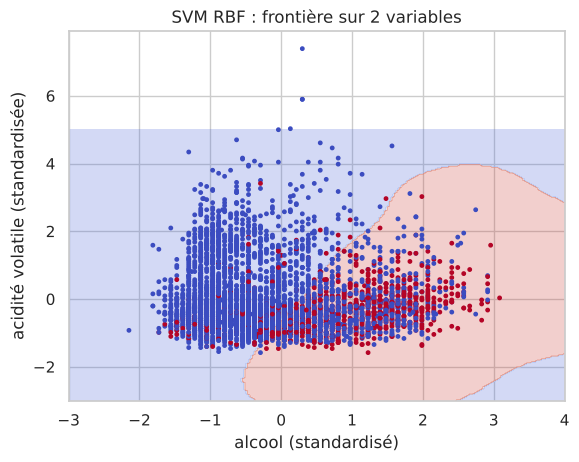

In [ ]:
deux = ["alcohol", "volatile acidity"]
sc2 = StandardScaler().fit(X_train11[deux])
X2 = sc2.transform(X_train11[deux])

svm2 = SVC(kernel="rbf", class_weight="balanced").fit(X2, y_train)
print("F1 sur le train, avec 2 variables :", round(f1_score(y_train, svm2.predict(X2)), 3))

xx, yy = np.meshgrid(np.linspace(-3, 4, 200), np.linspace(-3, 5, 200))
zone = svm2.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
plt.contourf(xx, yy, zone, alpha=0.25, cmap="coolwarm")
plt.scatter(X2[:, 0], X2[:, 1], c=y_train, s=6, cmap="coolwarm")
plt.xlabel("alcool (standardisé)")
plt.ylabel("acidité volatile (standardisée)")
plt.title("SVM RBF : frontière sur 2 variables")
plt.show()

Résultat : les bons vins (points rouges) sont surtout à droite, avec beaucoup d'alcool et peu d'acidité volatile, mais ils sont mélangés aux autres (points bleus). La zone rouge est celle où le SVM annonce « bon vin ». Avec deux variables, le F1 sur le train est de 0,522 : les classes se recouvrent beaucoup.

#### 2.2.e Random Forest

C'est la moyenne de beaucoup d'arbres, chacun appris sur un échantillon différent des vins et des variables. Elle garde la souplesse des arbres et apprend moins le bruit. Elle n'a pas besoin de standardisation. Le graphique montre l'effet du nombre d'arbres.

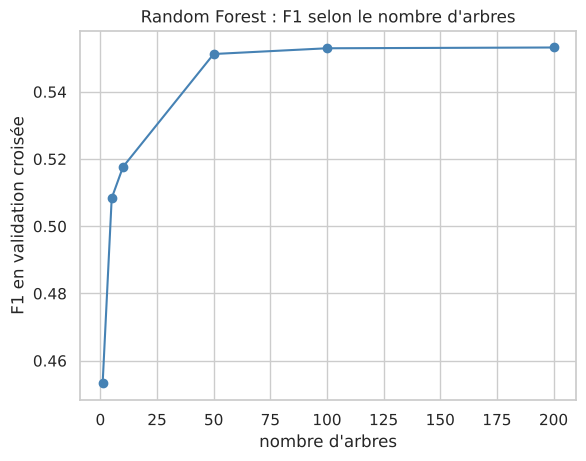

In [ ]:
nb_arbres = [1, 5, 10, 50, 100, 200]
f1_rf = []
for n in nb_arbres:
    rf = RandomForestClassifier(n_estimators=n, random_state=42, class_weight="balanced", n_jobs=-1)
    f1_rf.append(cross_val_score(rf, X_train11, y_train, cv=5, scoring="f1").mean())

plt.plot(nb_arbres, f1_rf, marker="o", color="steelblue")
plt.xlabel("nombre d'arbres")
plt.ylabel("F1 en validation croisée")
plt.title("Random Forest : F1 selon le nombre d'arbres")
plt.show()

Résultat : avec 1 arbre, le F1 est de 0,453. Il monte à 0,551 avec 50 arbres, puis il reste presque constant (0,553 avec 100 et 200 arbres).

#### 2.2.f Les cinq modèles utilisés dans la suite
Nous regroupons les cinq modèles dans un dictionnaire. Ce sont ceux que nous évaluons en 2.3 puis que nous optimisons en 2.4.

In [ ]:
modeles = {
    "Régression logistique": Pipeline([("scaler", StandardScaler()),
                                       ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
    "k-NN": Pipeline([("scaler", StandardScaler()),
                      ("model", KNeighborsClassifier())]),
    "Arbre de décision": Pipeline([("scaler", StandardScaler()),
                                   ("model", DecisionTreeClassifier(random_state=42, class_weight="balanced"))]),
    "SVM": Pipeline([("scaler", StandardScaler()),
                     ("model", SVC(class_weight="balanced"))]),
    "Random Forest": Pipeline([("scaler", StandardScaler()),
                               ("model", RandomForestClassifier(random_state=42, class_weight="balanced", n_jobs=-1))]),
}
list(modeles)

['Régression logistique', 'k-NN', 'Arbre de décision', 'SVM', 'Random Forest']

### 2.3 Évaluation des modèles

Nous évaluons les modèles avec leurs réglages par défaut, en validation croisée à 5 plis sur le train : le train est coupé en 5 parties, on entraîne sur 4 et on teste sur la 5e, et on recommence 5 fois. Le scaler est recalculé dans chaque pli (grâce au `Pipeline`), donc le test n'est pas utilisé.

#### - Évaluation des modèles à l'aide de métriques pertinentes :
- Accuracy, précision, rappel, F1-score.
- Matrice de confusion.
- Courbe ROC et AUC.

L'accuracy est élevée même pour un mauvais modèle, car il y a 81 % de mauvais vins. La précision dit, parmi les vins annoncés bons, combien le sont vraiment. Le rappel dit, parmi les vrais bons vins, combien on en trouve. Le F1 est la moyenne des deux, c'est notre mesure principale. Le tableau donne la moyenne ± l'écart-type sur les 5 plis.

In [ ]:
from sklearn.model_selection import cross_validate, cross_val_predict

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = ["accuracy", "precision", "recall", "f1", "roc_auc"]

f1_cv = {}
lignes = {}
for nom, modele in modeles.items():
    r = cross_validate(modele, X_train11, y_train, cv=cv, scoring=scores)
    lignes[nom] = [f"{r['test_' + s].mean():.3f} ± {r['test_' + s].std():.3f}" for s in scores]
    f1_cv[nom] = (r["test_f1"].mean(), r["test_f1"].std())

pd.DataFrame(lignes, index=["Accuracy", "Précision", "Rappel", "F1", "AUC"]).T

,Accuracy,Précision,Rappel,F1,AUC
Régression logistique,0.739 ± 0.017,0.404 ± 0.020,0.784 ± 0.033,0.533 ± 0.022,0.831 ± 0.013
k-NN,0.823 ± 0.011,0.546 ± 0.037,0.421 ± 0.022,0.475 ± 0.022,0.784 ± 0.022
Arbre de décision,0.781 ± 0.012,0.425 ± 0.029,0.420 ± 0.019,0.422 ± 0.018,0.643 ± 0.011
SVM,0.745 ± 0.008,0.411 ± 0.009,0.801 ± 0.021,0.543 ± 0.011,0.843 ± 0.008
Random Forest,0.827 ± 0.010,0.540 ± 0.026,0.574 ± 0.035,0.556 ± 0.028,0.849 ± 0.013


Nous avons tracé les matrices de confusion. En haut à gauche : les mauvais vins bien classés. En bas à droite : les bons vins bien classés. En haut à droite : les fausses alertes. En bas à gauche : les bons vins ratés.

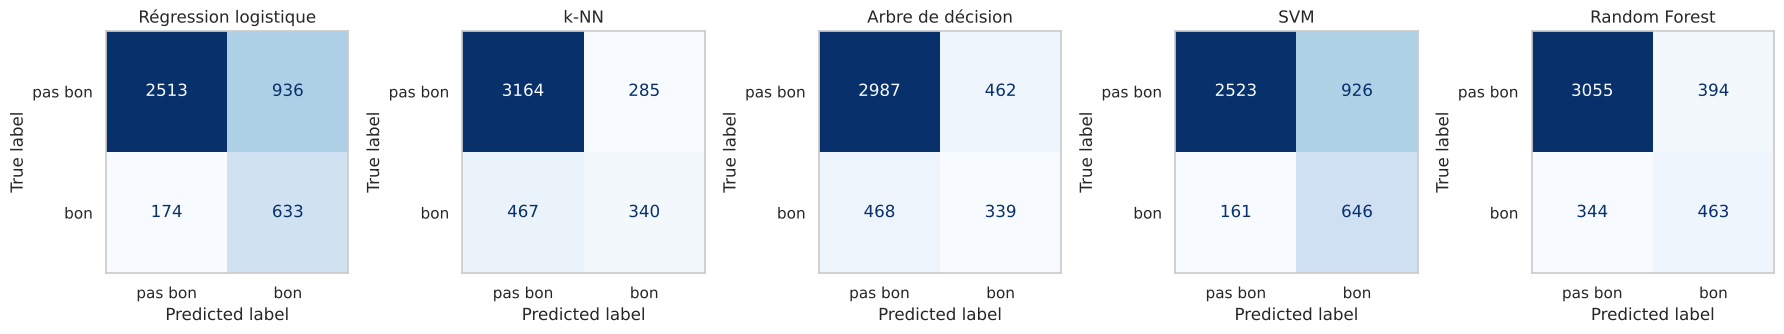

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.6))
for ax, (nom, modele) in zip(axes, modeles.items()):
    pred = cross_val_predict(modele, X_train11, y_train, cv=cv)
    ConfusionMatrixDisplay.from_predictions(y_train, pred, ax=ax, colorbar=False,
                                            display_labels=["pas bon", "bon"], cmap="Blues")
    ax.set_title(nom)
    ax.grid(False)
plt.tight_layout()
plt.show()

Nous avons tracé la courbe ROC : le taux de bons vins trouvés selon le taux de fausses alertes, pour tous les seuils. Plus la courbe est proche du coin en haut à gauche, mieux c'est. L'AUC est l'aire sous la courbe : 0,5 pour le hasard, 1 pour un modèle parfait.

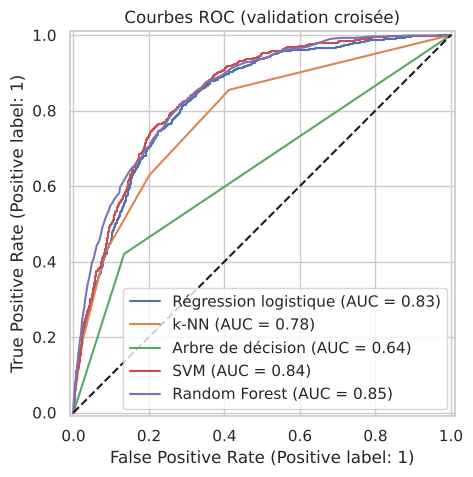

In [ ]:
plt.figure(figsize=(6, 5))
for nom, modele in modeles.items():
    if nom in ["Régression logistique", "SVM"]:
        s = cross_val_predict(modele, X_train11, y_train, cv=cv, method="decision_function")
    else:
        s = cross_val_predict(modele, X_train11, y_train, cv=cv, method="predict_proba")[:, 1]
    RocCurveDisplay.from_predictions(y_train, s, name=nom, ax=plt.gca())
plt.plot([0, 1], [0, 1], "k--")
plt.title("Courbes ROC (validation croisée)")
plt.show()

Résultat avec les réglages par défaut : l'accuracy va de 0,74 à 0,83 alors que la réponse « toujours pas bon » donne 0,81, elle ne sert donc pas à choisir.

Il y a 807 bons vins dans le train. La régression logistique en trouve 633 mais fait 936 fausses alertes. Le k-NN n'en trouve que 340, avec 285 fausses alertes. La Random Forest en trouve 463, avec 394 fausses alertes.

Sur la courbe ROC, la Random Forest (AUC de 0,85), le SVM (0,84) et la régression logistique (0,83) sont les meilleurs. Viennent ensuite le k-NN (0,78) et l'arbre (0,64).

#### - Comparaison des performances et interprétation des résultats.
Le graphique compare le F1 des cinq modèles. Le trait noir est l'écart-type : si deux traits se chevauchent, on ne peut pas dire qu'un modèle est meilleur que l'autre.

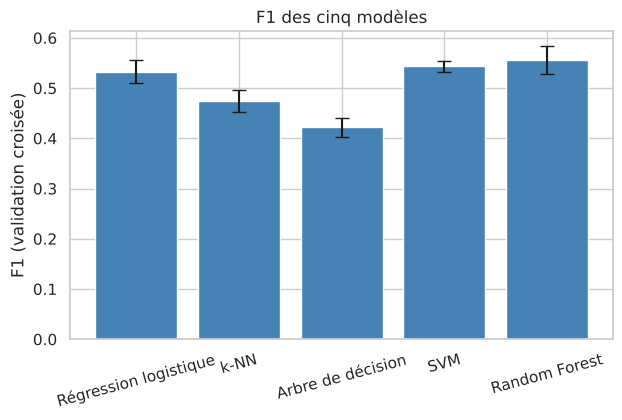

In [ ]:
plt.figure(figsize=(7, 4))
plt.bar(list(f1_cv), [v[0] for v in f1_cv.values()], yerr=[v[1] for v in f1_cv.values()],
        color="steelblue", capsize=5)
plt.ylabel("F1 (validation croisée)")
plt.xticks(rotation=15)
plt.title("F1 des cinq modèles")
plt.show()

Résultat : la Random Forest a le meilleur F1 (0,556), puis le SVM (0,543) et la régression logistique (0,533). Les écarts (0,013 et 0,023) sont plus petits que l'écart-type de la Random Forest (0,028), donc on ne peut pas les départager. Le k-NN (0,475) et l'arbre (0,422) sont plus bas, avec des écarts de 0,081 et 0,134.

#### - Identification du modèle le plus performant selon un compromis biais/variance.
Un biais élevé (sous-apprentissage) veut dire que le modèle est trop simple : il est moyen même sur le train. Une variance élevée (surapprentissage) veut dire que le modèle est très bon sur le train mais moins bon sur de nouveaux vins. Nous comparons le F1 sur le train au F1 en validation croisée. Un grand écart indique de la variance, des scores moyens des deux côtés indiquent du biais.

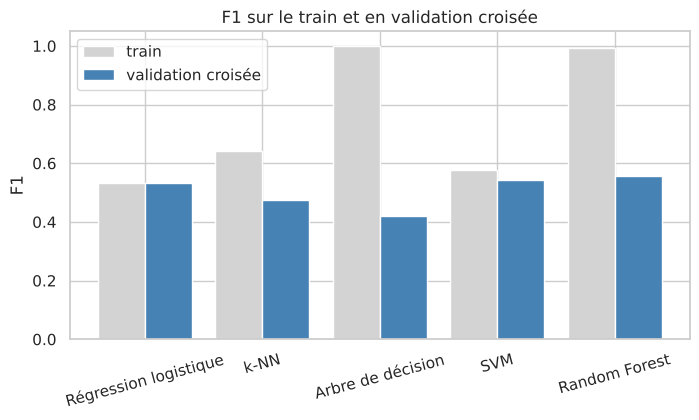

In [ ]:
f1_train = {}
for nom, modele in modeles.items():
    modele.fit(X_train11, y_train)
    f1_train[nom] = f1_score(y_train, modele.predict(X_train11))

x = np.arange(len(modeles))
plt.figure(figsize=(8, 4))
plt.bar(x - 0.2, list(f1_train.values()), width=0.4, label="train", color="lightgray")
plt.bar(x + 0.2, [v[0] for v in f1_cv.values()], width=0.4, label="validation croisée", color="steelblue")
plt.xticks(x, list(modeles), rotation=15)
plt.ylabel("F1")
plt.legend()
plt.title("F1 sur le train et en validation croisée")
plt.show()

Résultat : pour la régression logistique, les deux F1 sont presque égaux (0,534 et 0,533) : le modèle est trop simple, c'est du biais. L'arbre a 1,00 sur le train et 0,42 en validation : il apprend par cœur, c'est de la variance. La Random Forest a aussi un grand écart (0,99 contre 0,556) mais elle a le F1 de validation le plus haut. Le SVM a un petit écart (0,578 contre 0,543) et un bon F1.

Nous choisissons sur la validation croisée, pas sur le train.

### 2.4 Optimisation des hyperparamètres

#### - Utilisation de techniques d'optimisation telles que :
- Grid Search : recherche exhaustive sur une grille d'hyperparamètres.
- Random Search : recherche aléatoire pour un gain de temps.

Un hyperparamètre est un réglage du modèle choisi avant l'entraînement (par exemple le nombre de voisins du k-NN). Jusqu'ici nous avons gardé les réglages par défaut. Nous cherchons maintenant de meilleurs réglages.

Le Grid Search essaie toutes les combinaisons d'une petite grille. Chaque combinaison est notée par validation croisée à 5 plis sur le train avec le F1, et nous gardons la meilleure. Nos grilles sont petites, donc nous utilisons seulement le Grid Search. Le Random Search sert pour de très grandes grilles. Le test n'est pas utilisé.

In [ ]:
grilles = {
    "Régression logistique": {"model__C": [0.01, 0.1, 1, 10]},
    "k-NN": {"model__n_neighbors": [3, 5, 11, 21], "model__weights": ["uniform", "distance"]},
    "Arbre de décision": {"model__max_depth": [3, 5, 10, None], "model__min_samples_leaf": [1, 10, 20]},
    "SVM": {"model__C": [0.1, 1, 10], "model__gamma": [0.01, 0.1, 1]},
    "Random Forest": {"model__n_estimators": [100, 300], "model__max_depth": [10, None], "model__min_samples_leaf": [1, 3, 5]},
}

modeles_opt = {}
lignes = {}
for nom, modele in modeles.items():
    recherche = GridSearchCV(modele, grilles[nom], cv=cv, scoring="f1", n_jobs=-1)
    recherche.fit(X_train11, y_train)
    modeles_opt[nom] = recherche.best_estimator_
    lignes[nom] = {"F1 par défaut": round(f1_cv[nom][0], 3),
                   "F1 optimisé": round(recherche.best_score_, 3),
                   "Meilleurs hyperparamètres": {k.replace("model__", ""): v for k, v in recherche.best_params_.items()}}

pd.DataFrame(lignes).T

,F1 par défaut,F1 optimisé,Meilleurs hyperparamètres
Régression logistique,0.533,0.539,{'C': 0.01}
k-NN,0.475,0.49,"{'n_neighbors': 5, 'weights': 'distance'}"
Arbre de décision,0.422,0.511,"{'max_depth': 5, 'min_samples_leaf': 10}"
SVM,0.543,0.544,"{'C': 1, 'gamma': 0.1}"
Random Forest,0.556,0.563,"{'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 100}"


Résultat : le F1 change peu, sauf pour l'arbre. Régression logistique 0,533 → 0,539, k-NN 0,475 → 0,490, arbre 0,422 → 0,511, SVM 0,543 → 0,544, Random Forest 0,556 → 0,563.

Sauf pour l'arbre, les gains sont plus petits que l'écart-type : les réglages par défaut étaient déjà corrects. L'arbre progresse parce que sa profondeur est limitée à 5, ce qui l'empêche d'apprendre par cœur.

#### - Évaluation des modèles optimisés via validation croisée (k-fold).
Nous refaisons la validation croisée à 5 plis avec les modèles optimisés.

In [ ]:
lignes = {}
f1_opt = {}
for nom, modele in modeles_opt.items():
    r = cross_validate(modele, X_train11, y_train, cv=cv, scoring=scores)
    lignes[nom] = [f"{r['test_' + s].mean():.3f} ± {r['test_' + s].std():.3f}" for s in scores]
    f1_opt[nom] = (r["test_f1"].mean(), r["test_f1"].std())

pd.DataFrame(lignes, index=["Accuracy", "Précision", "Rappel", "F1", "AUC"]).T

,Accuracy,Précision,Rappel,F1,AUC
Régression logistique,0.742 ± 0.013,0.408 ± 0.017,0.796 ± 0.035,0.539 ± 0.021,0.828 ± 0.014
k-NN,0.828 ± 0.009,0.563 ± 0.030,0.435 ± 0.027,0.490 ± 0.023,0.793 ± 0.022
Arbre de décision,0.703 ± 0.019,0.372 ± 0.017,0.818 ± 0.041,0.511 ± 0.017,0.788 ± 0.025
SVM,0.745 ± 0.008,0.412 ± 0.011,0.802 ± 0.025,0.544 ± 0.014,0.842 ± 0.008
Random Forest,0.792 ± 0.015,0.469 ± 0.025,0.705 ± 0.029,0.563 ± 0.026,0.847 ± 0.011


Résultat : le F1 en validation croisée est de 0,563 pour la Random Forest, 0,544 pour le SVM, 0,539 pour la régression logistique, 0,511 pour l'arbre et 0,490 pour le k-NN. Le classement ne change pas. L'écart entre la Random Forest et le SVM (0,019) reste plus petit que l'écart-type (0,026).

#### 2.4.a Évaluation finale sur le jeu de test
Nous utilisons le jeu de test une seule fois, à la fin, sur des vins que les modèles n'ont jamais vus.

In [ ]:
lignes = {}
for nom, modele in modeles_opt.items():
    pred = modele.predict(X_test11)
    if nom in ["Régression logistique", "SVM"]:
        s = modele.decision_function(X_test11)
    else:
        s = modele.predict_proba(X_test11)[:, 1]
    lignes[nom] = [round(accuracy_score(y_test, pred), 3), round(precision_score(y_test, pred), 3),
                   round(recall_score(y_test, pred), 3), round(f1_score(y_test, pred), 3),
                   round(roc_auc_score(y_test, s), 3)]

pd.DataFrame(lignes, index=["Accuracy", "Précision", "Rappel", "F1", "AUC"]).T

,Accuracy,Précision,Rappel,F1,AUC
Régression logistique,0.733,0.399,0.797,0.531,0.817
k-NN,0.847,0.633,0.460,0.533,0.826
Arbre de décision,0.703,0.369,0.792,0.503,0.799
SVM,0.736,0.404,0.827,0.543,0.853
Random Forest,0.816,0.510,0.762,0.611,0.874


Résultat sur le test (1064 vins dont 202 bons) : la Random Forest a le meilleur F1 (0,611) et la meilleure AUC (0,874). Elle trouve 76 % des bons vins avec une précision de 0,51. Les autres modèles ont un F1 de 0,50 à 0,54. Le test confirme donc le classement.

Le k-NN a la meilleure accuracy (0,85) mais il ne trouve que 46 % des bons vins : l'accuracy ne sert pas à choisir.

#### 2.4.b Pourquoi la Random Forest ?
Nous avons tracé l'importance des variables de la Random Forest optimisée.

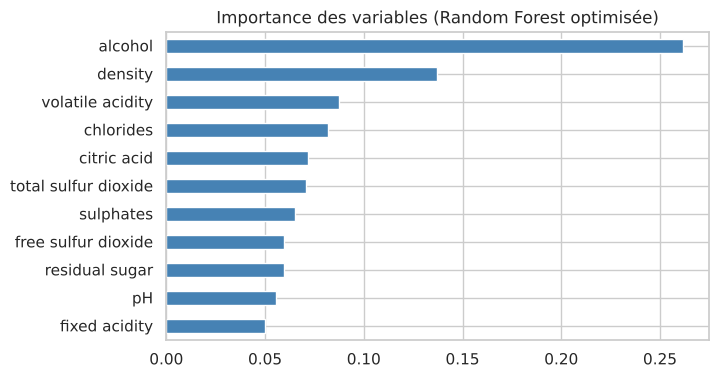

In [ ]:
rf = modeles_opt["Random Forest"]["model"]
pd.Series(rf.feature_importances_, index=variables).sort_values().plot.barh(color="steelblue", figsize=(7, 4))
plt.title("Importance des variables (Random Forest optimisée)")
plt.show()

Résultat : l'alcool est en tête (0,26), puis la densité (0,14). C'est la même conclusion qu'en 2.1.

#### 2.4.c Conclusion : pourquoi la Random Forest est le modèle retenu

Nous retenons la Random Forest. Elle a le meilleur F1 en validation croisée (0,563) et sur le test (0,611), et la meilleure AUC (0,847 en validation, 0,874 sur le test). Nos raisons :

- Elle fait la moyenne de beaucoup d'arbres, donc elle garde leur souplesse sans apprendre le bruit comme un arbre seul (F1 de 0,51 pour l'arbre optimisé).
- Elle n'a pas besoin de standardisation et réagit peu aux valeurs aberrantes.
- Elle trouve des bons vins sans trop de fausses alertes : rappel de 0,70 et précision de 0,47 en validation, contre un rappel de 0,80 et une précision de 0,41 pour le SVM et la régression logistique.
- Elle donne l'importance des variables, ce qui aide à expliquer le résultat.

Une précaution : en validation croisée, son avance sur le SVM (0,019) et la régression logistique (0,024) est plus petite que l'écart-type (0,026). Nous ne pouvons donc pas dire qu'elle est meilleure qu'eux. Elle est meilleure que l'arbre et le k-NN, et le test va dans le même sens.

Limites : le F1 reste modeste (environ 0,56), à peu près un vin annoncé « bon » sur deux l'est vraiment. La note est subjective et nos mesures ne contiennent ni le cépage, ni le producteur, ni le prix.